In [28]:
import sys
if '../' not in sys.path:
    sys.path.append('../')

In [29]:
import os
import numpy as np
from hmp_utils import AmassEvaluationFrames, SrnnEvaluationFrames, load_sets_by_dataset_dict
from hmp_utils import H36MConstants,SmplConstants,MocapLoader,MocapData,RotConverter

In [30]:
actions = [
            "walking",
            "eating",
            "smoking",
            "discussion",
            "directions",
            "greeting",
            "phoning",
            "posing",
            "purchases",
            "sitting",
            "sittingdown",
            "takingphoto",
            "waiting",
            "walkingdog",
            "walkingtogether",
        ]
def load_h36m_sub(data_dir,subjects,mocap_loader):
    dataset=[]
    for subj in subjects:
        for action in actions:
            for subact in [1, 2]:  # subactions
                filename = "{0}/S{1}/{2}_{3}.txt".format(
                    data_dir, subj, action, subact
                )
                dataset.append(mocap_loader.load_mocap(filename))
    return dataset

In [31]:
from tqdm import tqdm
def load_amass_sub(data_dir,set,mocap_loader):
    dataset=[]
    for key, path_list in set.items():
        for path in tqdm(path_list, desc=f"Loading dataset - {key}"):
            dataset.append(mocap_loader.load_mocap(path))
    return dataset

In [32]:
home_path = os.path.expanduser("~")

dataset_name="h36m"
dataset_name="amass"

data_dir_h36m = "datasets/h3.6m/dataset"
data_dir_amass = "datasets/AMASS_H"
amass_split_file = "pt_pvr/PVRED/dataset/amass_split"
num_joint_amass= 24

AMASS_TARGET_FRAMERATE = 25

if dataset_name == "h36m":
    data_dir = os.path.join(home_path, data_dir_h36m)
    framerate=25.
    bodyConstants =H36MConstants
    mocap_loader=MocapLoader(bodyConstants.BODY_MODEL_TYPE, range(bodyConstants.NUM_KEYPOINTS), framerate)
    evaluation_frames=SrnnEvaluationFrames
    train_set = load_h36m_sub(data_dir,[1, 6, 7, 8, 9],mocap_loader)
    valid_set = load_h36m_sub(data_dir,[11],mocap_loader)
    test_set = load_h36m_sub(data_dir,[5],mocap_loader)

elif dataset_name == "amass":
    data_dir = os.path.join(home_path, data_dir_amass)
    framerate=AMASS_TARGET_FRAMERATE
    bodyConstants =SmplConstants
    mocap_loader = MocapLoader(
                body_model_type=bodyConstants.BODY_MODEL_TYPE,
                keypoint_ids_to_load=range(bodyConstants.NUM_KEYPOINTS),
                target_framerate=AMASS_TARGET_FRAMERATE,
            )
    evaluation_frames=AmassEvaluationFrames
    amass_split_file = os.path.join(home_path, amass_split_file)
    dataset_dict = load_sets_by_dataset_dict(amass_split_file, data_dir)
    train_set = load_amass_sub(data_dir, dataset_dict['train'] ,mocap_loader)
    valid_set = load_amass_sub(data_dir, dataset_dict['validation'] ,mocap_loader)
    test_set = load_amass_sub(data_dir, dataset_dict['test'] ,mocap_loader)

Loading dataset - BMLmovi:   1%|          | 15/1266 [00:00<00:09, 136.53it/s]

Loading dataset - Transitions: 100%|██████████| 11/11 [00:00<00:00, 124.87it/s]


In [33]:
from hmp_utils import CameraOrientation,pose_animation,AnimationMode

def print_skel(keypoints_positions):
    motions_list = [keypoints_positions]
    subplot_ids = [0]
    subplot_titles = ['single motion']
    camera_orientations = [CameraOrientation(90, -90)]
    pose_animation(motions_list, bodyConstants.PARENTS, framerate, subplot_ids=subplot_ids, 
                camera_orientations=camera_orientations, subplot_titles=subplot_titles,
                animation_mode=AnimationMode.HTML)

In [34]:
from hmp_utils import SpectrumMetricsProcessor
from hmp_utils import ForwardKinematics,FkReturnType
fk_processor = ForwardKinematics(
                bodyConstants.OFFSETS, bodyConstants.PARENTS
            )
fk_processor.set_body_model_type(bodyConstants.BODY_MODEL_TYPE)

def comute_psd_set(set):
    if dataset_name == "h36m":
        frames=evaluation_frames.get_spectrum_frames(num_frames_list=[len(mocap.rots) for mocap in set])
    elif dataset_name == "amass":
        frames=evaluation_frames.get_spectrum_frames(num_frames_list=[len(mocap.rots) for mocap in set],framerate=framerate)
    sp_set=[]
    for mocap_idx in range(len(set)):
        # print("seqs_shape",set[mocap_idx].rots.shape)
        for seq_idx in range(len(frames[mocap_idx])):
            sp_set.append(set[mocap_idx].rots[frames[mocap_idx][seq_idx],:,:])

    if POS==True:
        print("compute fk")
        sp_set=fk_processor.compute_fk(np.array(sp_set), apply_root_rotation=False,return_type=FkReturnType.POSITIONS)
        # print_skel(sp_set[45])  

    if EULER==True:
        print("compute euler")
        sp_set=RotConverter.aa2euler(sp_set,eul_seq='xyz') 
            
    
    return SpectrumMetricsProcessor.power_spectral_density(seq_t=sp_set,framerate=framerate,joints_to_compute=bodyConstants.MAJOR_JOINTS,normalize=True,remove_zero_freq=True)

In [35]:
POS=True
EULER=False


psd_train=comute_psd_set(train_set)
psd_valid=comute_psd_set(valid_set)
psd_test=comute_psd_set(test_set)
print("psd_train",psd_train.shape)
print("psd_valid",psd_valid.shape)
print("psd_test",psd_test.shape)

compute fk
compute fk
compute fk
psd_train (12, 20, 3)
psd_valid (12, 20, 3)
psd_test (12, 20, 3)


In [36]:
major_joints_zeros=[]

def clean_psd(psd):
    idx=[]
    psd_shape=psd.shape
    psd=psd.reshape(psd.shape[0],-1)
    for i in range(psd.shape[1]):
        if np.sum(psd[:,i])==0:
            idx.append(i) 
    psd=np.delete(psd,idx,axis=1)
    for idxx in idx:
        major_joints_zeros.append(bodyConstants.JOINT_NAMES[bodyConstants.MAJOR_JOINTS[int(idxx/3)]])
    psd=psd.reshape(psd_shape[0],-1,psd_shape[-1])
    return psd

In [37]:
import matplotlib.pyplot as plt

def print_psd(psd):
    for i in range(psd.reshape(psd.shape[0],-1).shape[1]):
        plt.plot(psd.reshape(psd.shape[0],-1)[:,i])
        plt.grid()
        plt.show()


In [38]:
import matplotlib.pyplot as plt
symbols=['--','-*','o']
def print_psds(psd,major_joints_zeros):
    MJ=[bodyConstants.JOINT_NAMES[i] for i in bodyConstants.MAJOR_JOINTS]
    for joint in major_joints_zeros:
        MJ.remove(joint)
    for i in range(psd[0].reshape(psd[0].shape[0],-1).shape[1]):
        for jj,psd_it in enumerate(psd):
            plt.plot(psd_it.reshape(psd_it.shape[0],-1)[:,i],symbols[jj])
        plt.title(MJ[int(i/3)])
        plt.grid()
        plt.show()

In [39]:
SpectrumMetricsProcessor.ps_entropy(psd_test)

nan

20
train_psd (12, 16, 3)
Wasserstein distance
train-test:  0.022078071660130722
train-valid:  0.01744573858163392
test-valid:  0.022385494769449146
js divergence
train-test:  0.00017943245526075817
train-valid:  0.0001630833617959779
test-valid:  0.0002013200361149828
kl divergence
train-test:  0.0007120030749373703
train-valid:  0.0006459539754411889
test-valid:  0.0008093557478847354
test-train:  0.0007238935446268717
valid-train:  0.0006593988926705728
valid-test:  0.0008019336400694891


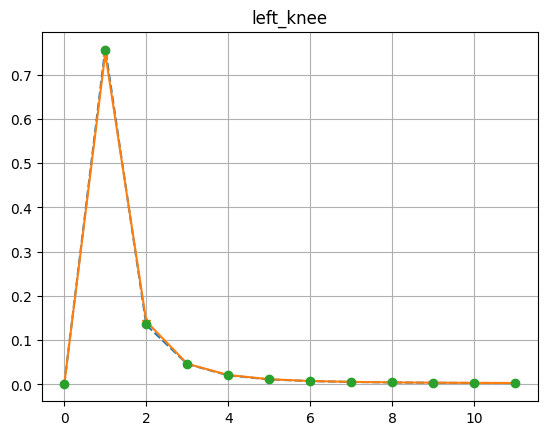

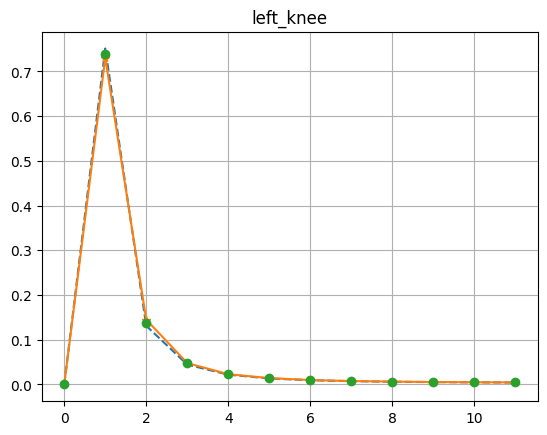

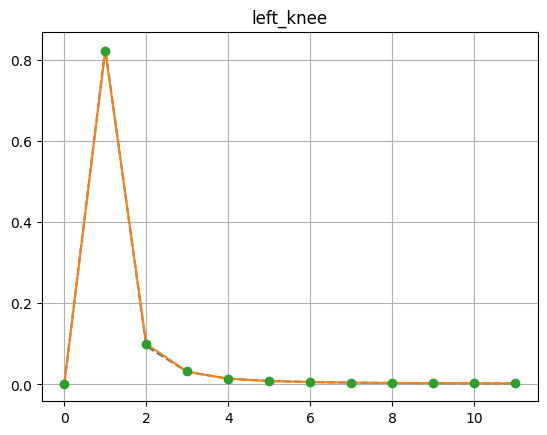

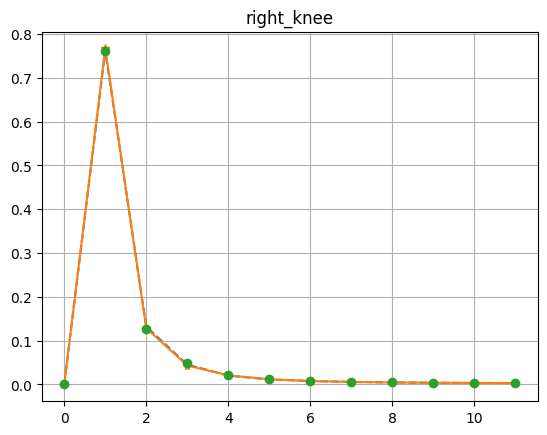

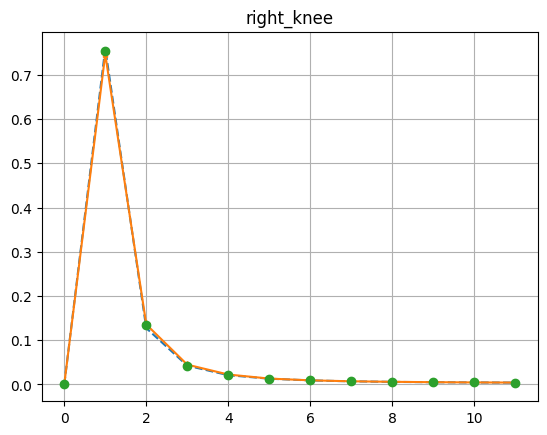

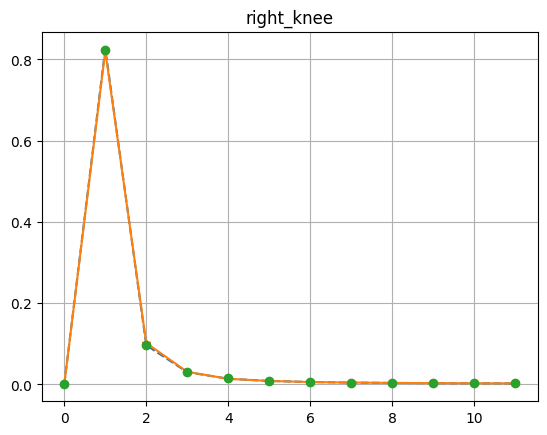

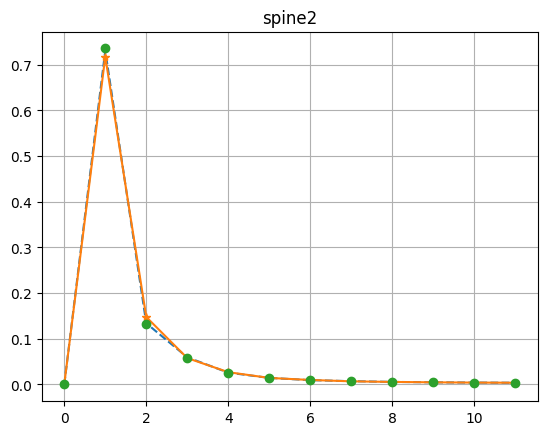

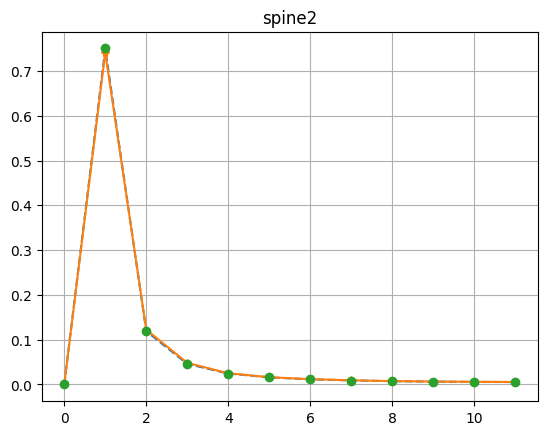

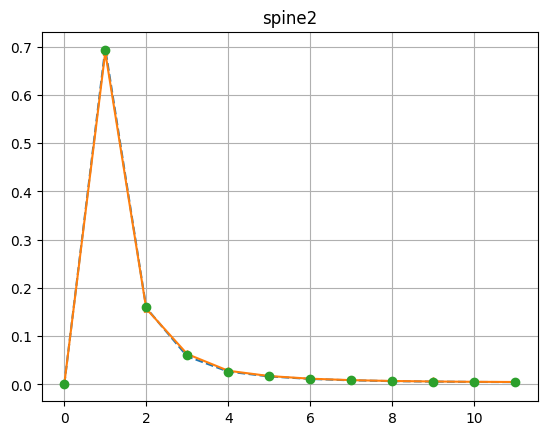

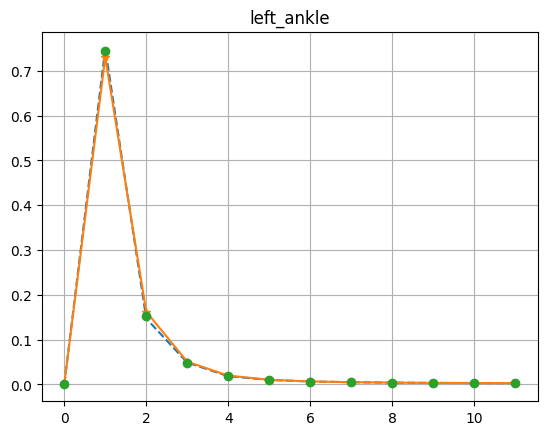

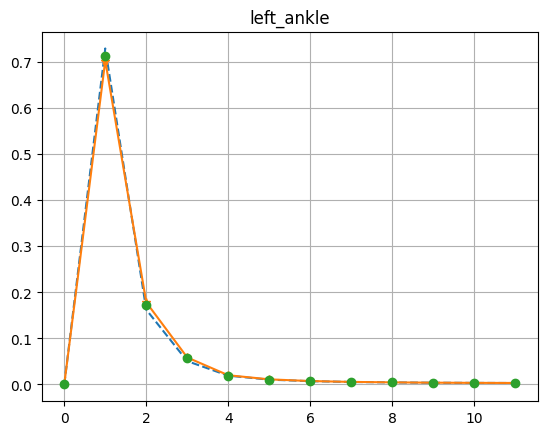

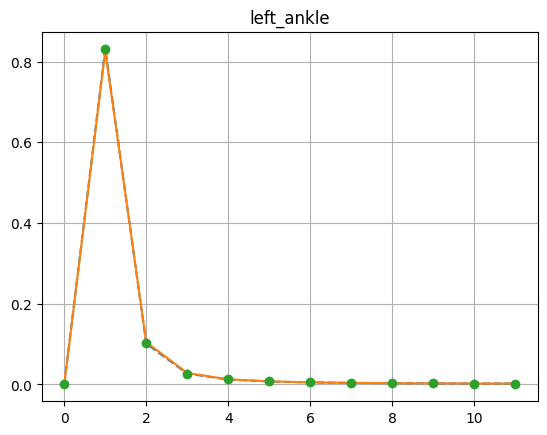

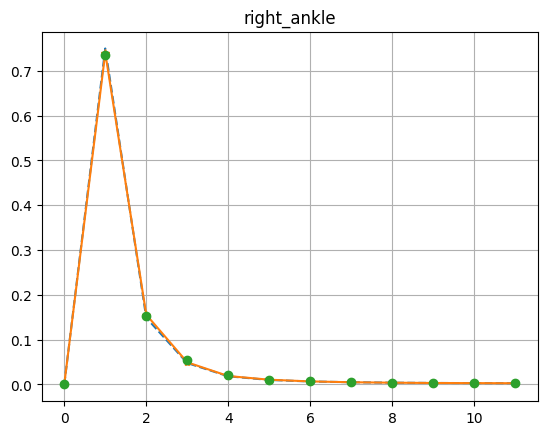

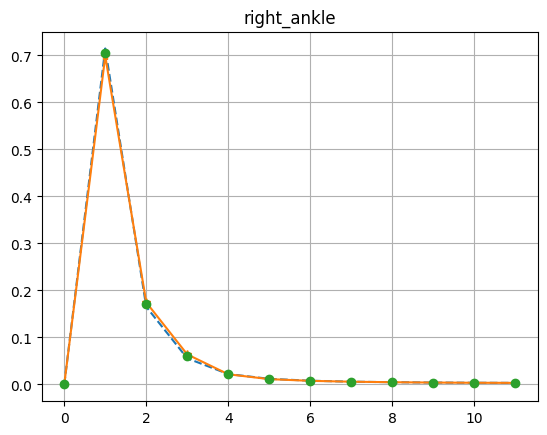

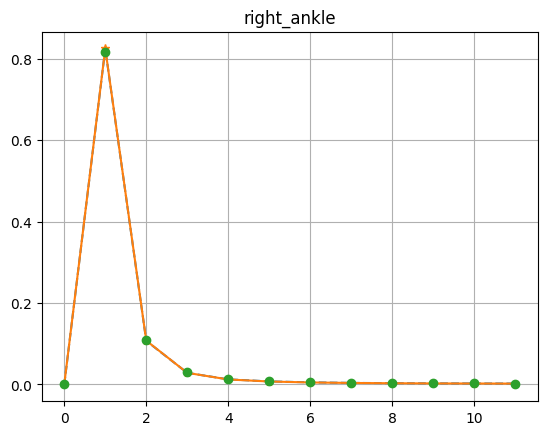

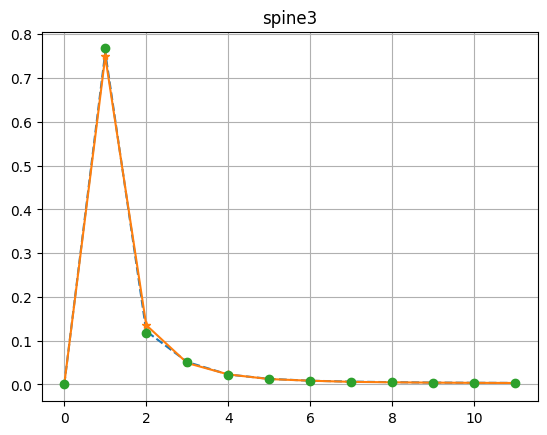

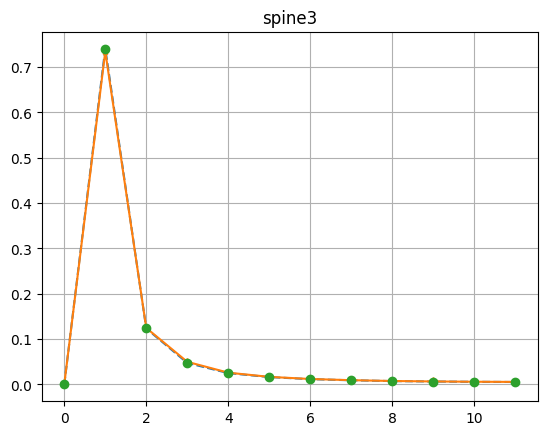

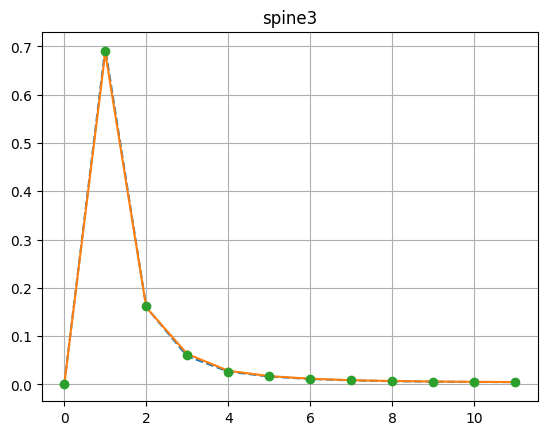

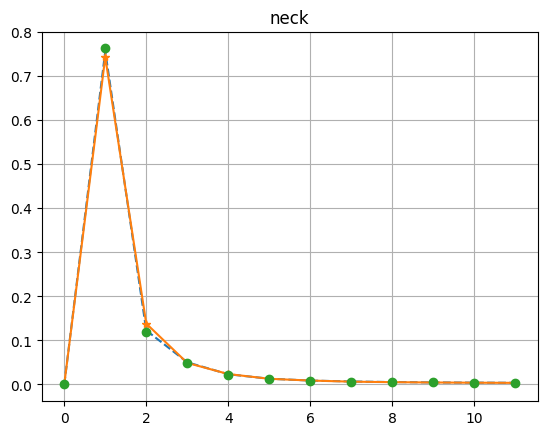

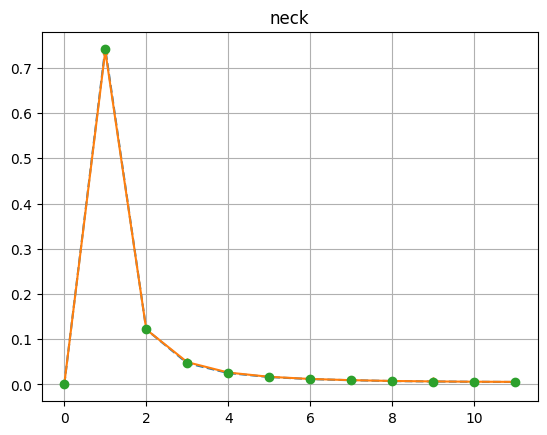

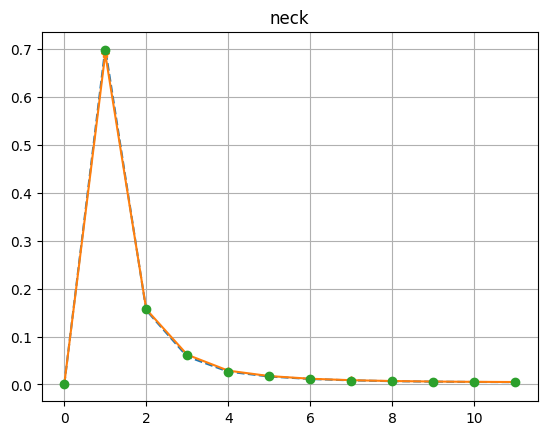

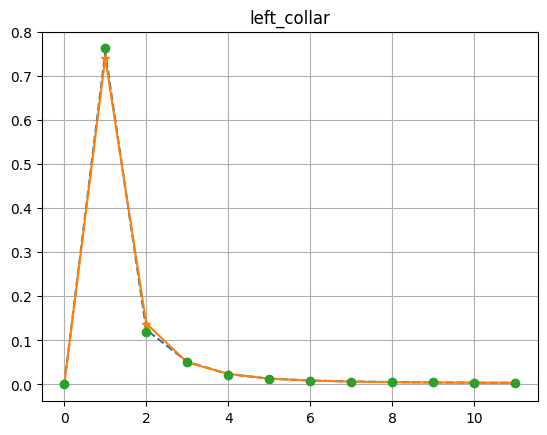

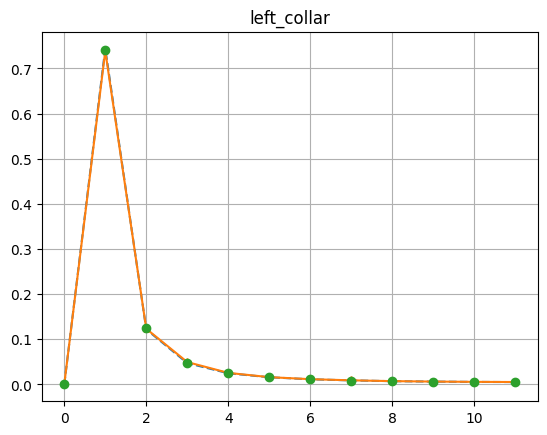

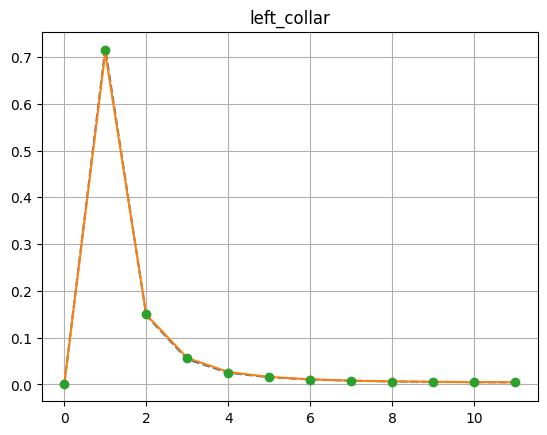

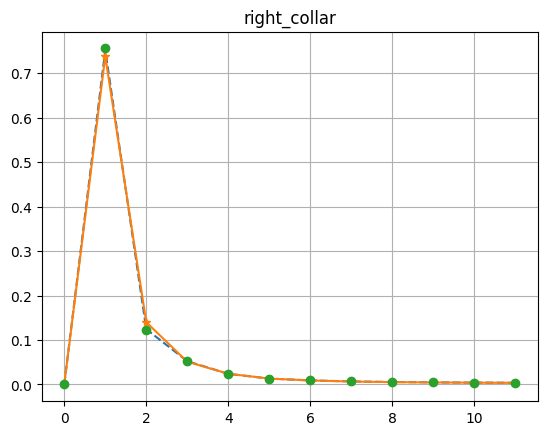

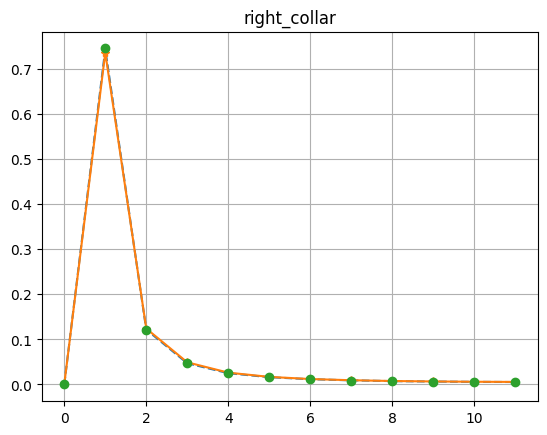

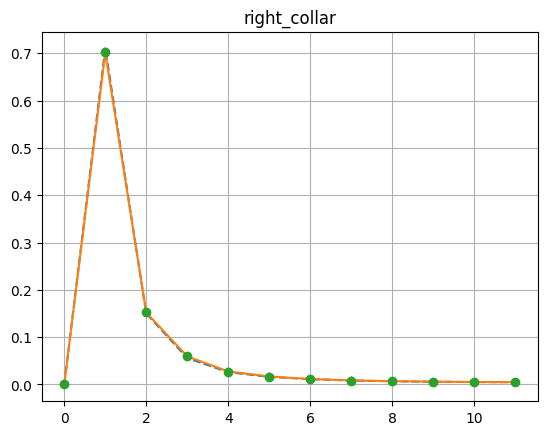

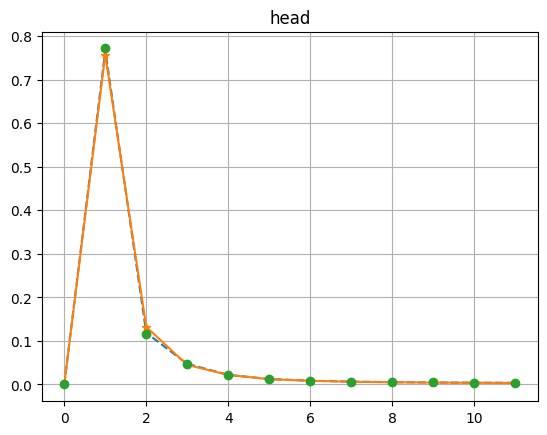

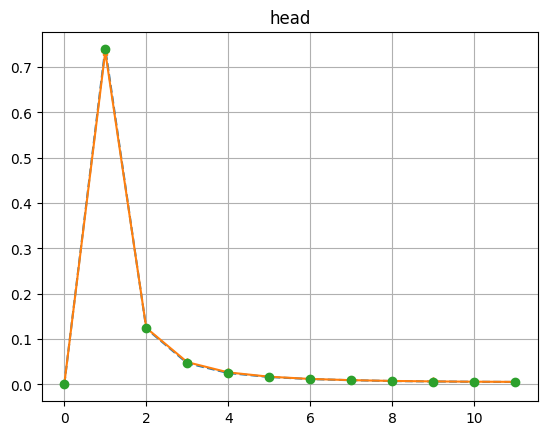

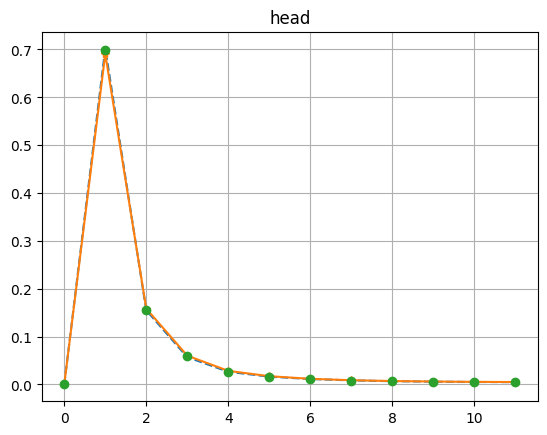

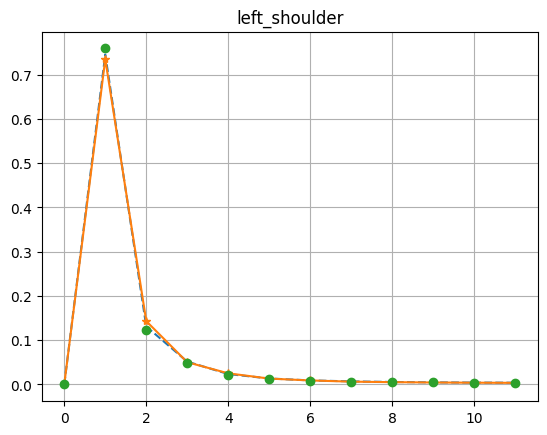

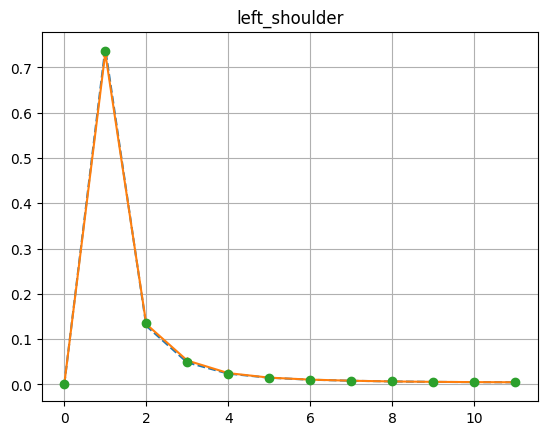

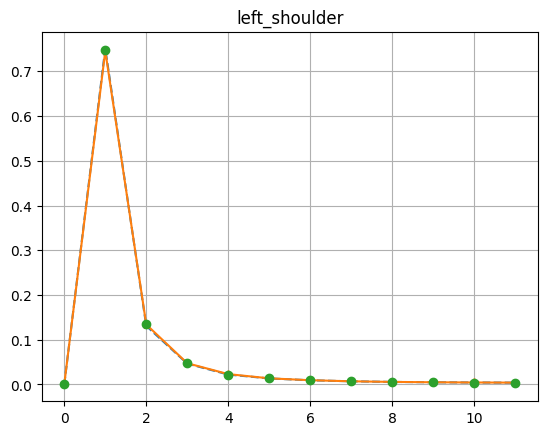

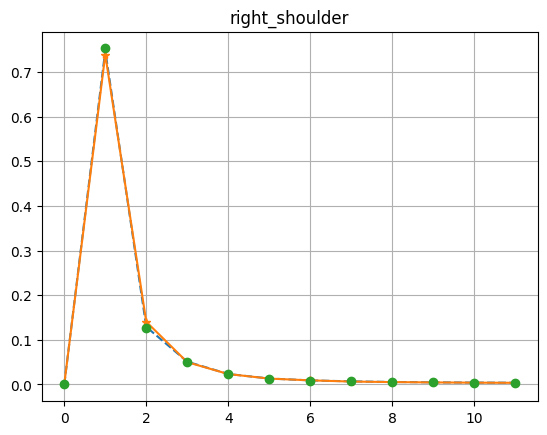

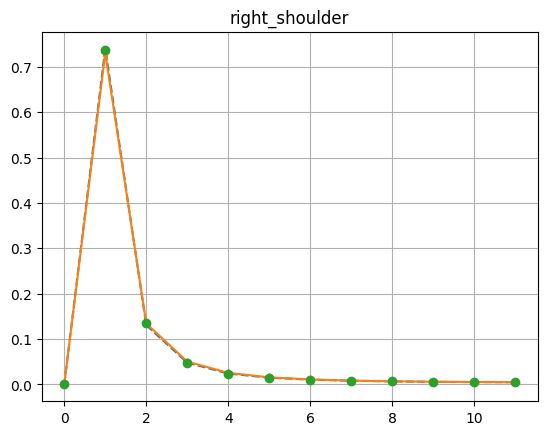

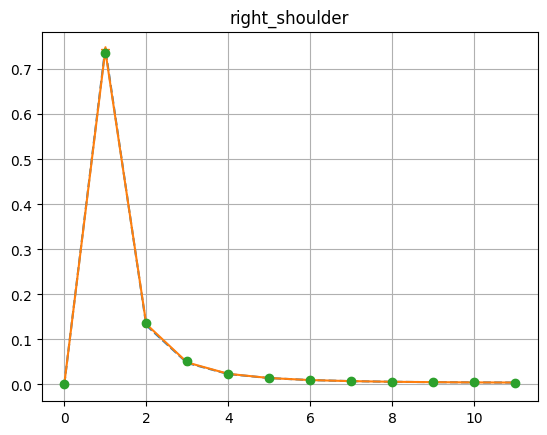

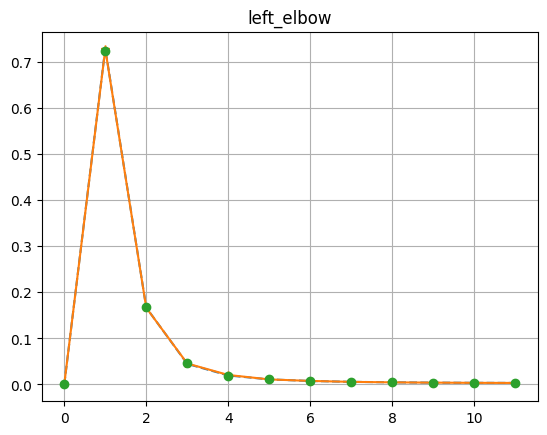

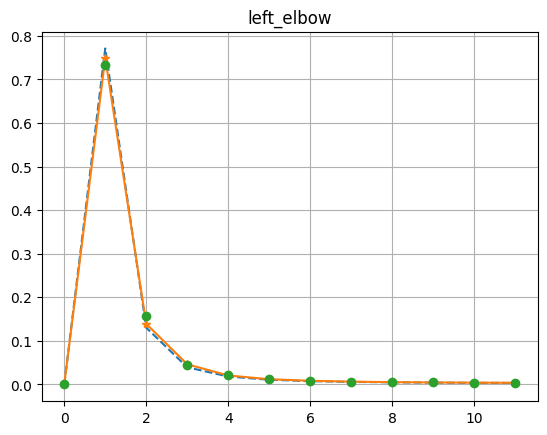

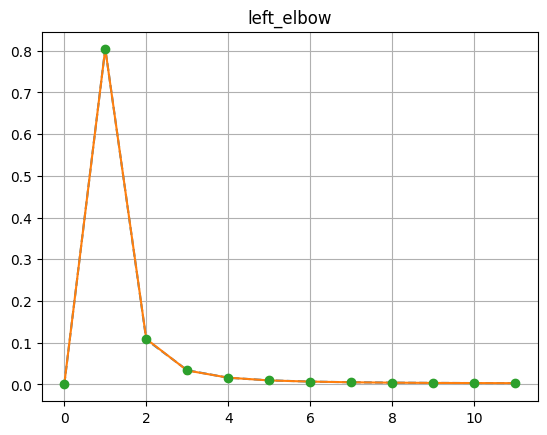

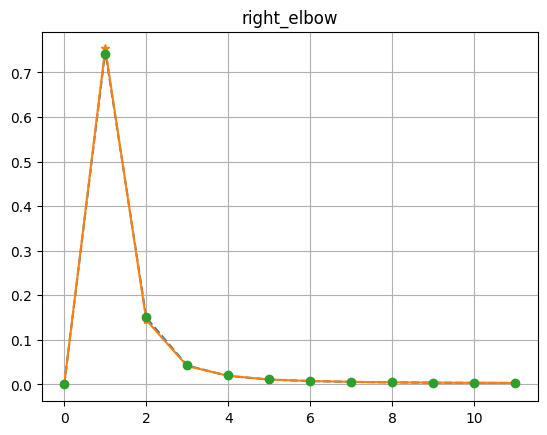

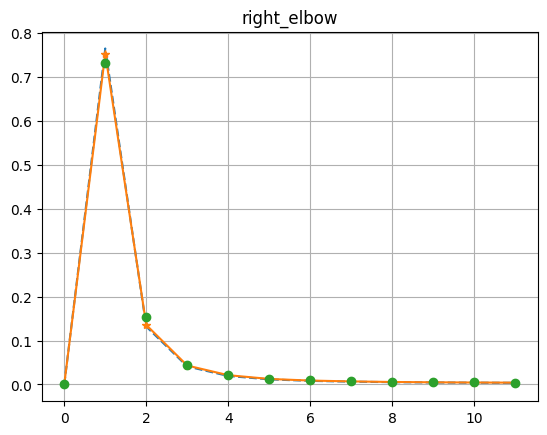

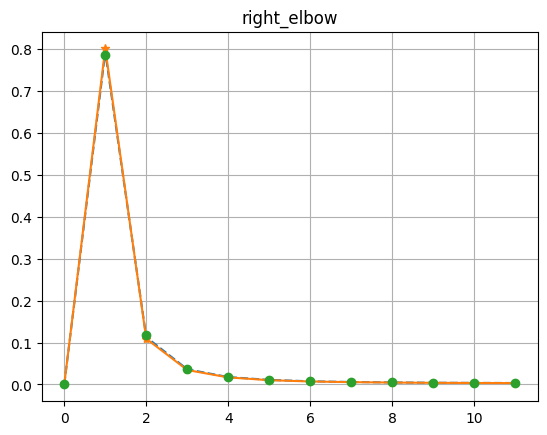

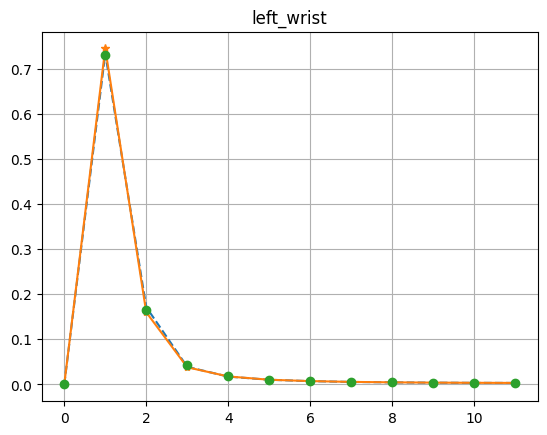

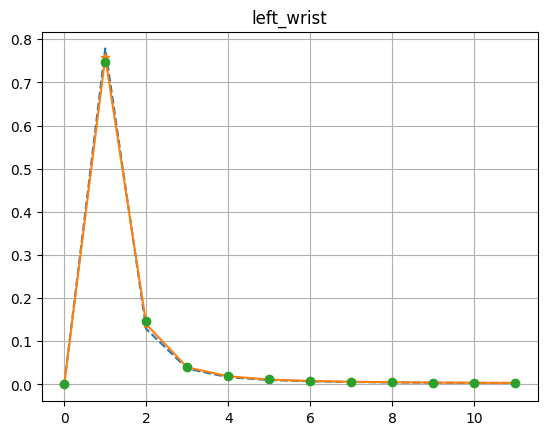

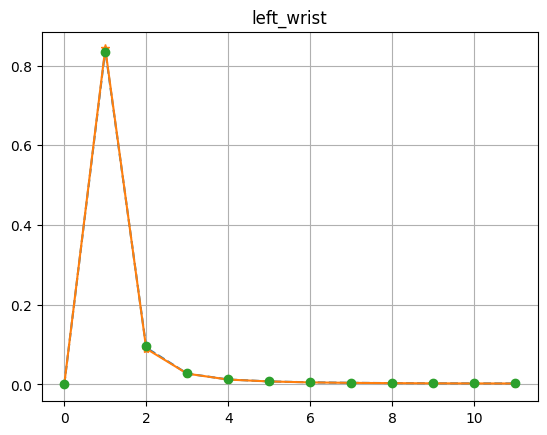

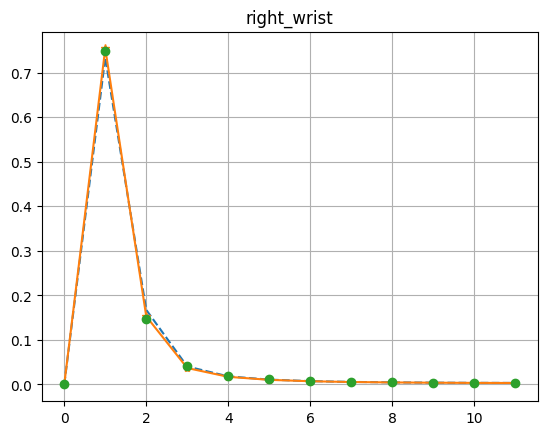

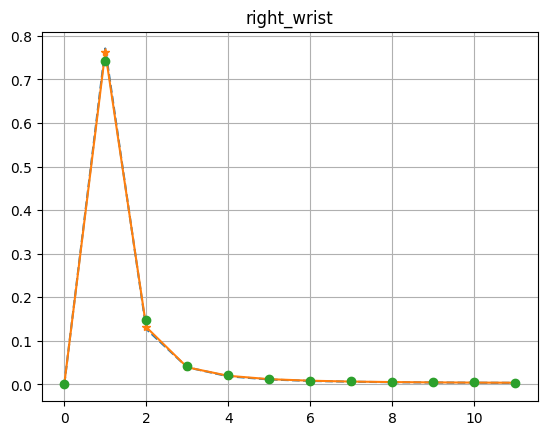

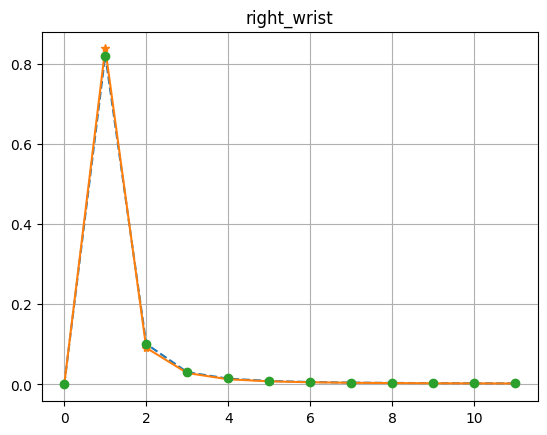

In [40]:
# train_psd=(get_psd(train_seqs))
# test_psd=(get_psd(test_seqs))
# valid_psd=(get_psd(valid_seqs))
major_joints_zeros=[]
train_psd=clean_psd(psd_train)
test_psd=clean_psd(psd_test)
valid_psd=clean_psd(psd_valid)

np.save(dataset_name+"_"+str(framerate)+"_train_psd",psd_train)
np.save(dataset_name+"_"+str(framerate)+"_test_psd",psd_test)
np.save(dataset_name+"_"+str(framerate)+"_validation_psd",psd_valid)

print(len(bodyConstants.MAJOR_JOINTS))
print("train_psd",train_psd.shape)

major_joints_zeros=list(set(major_joints_zeros))
# train_psd=psd_train
# test_psd=psd_test
# valid_psd=psd_valid
from hmp_utils import SpectrumMetricsProcessor
print('Wasserstein distance')
print('train-test: ',SpectrumMetricsProcessor.wasserstein_distance(train_psd,test_psd))
print('train-valid: ',SpectrumMetricsProcessor.wasserstein_distance(train_psd,valid_psd))
print('test-valid: ',SpectrumMetricsProcessor.wasserstein_distance(test_psd,valid_psd))

print('js divergence')
print('train-test: ',SpectrumMetricsProcessor.js_divergence(train_psd,test_psd))
print('train-valid: ',SpectrumMetricsProcessor.js_divergence(train_psd,valid_psd))
print('test-valid: ',SpectrumMetricsProcessor.js_divergence(test_psd,valid_psd))

print('kl divergence')
print('train-test: ',SpectrumMetricsProcessor.kl_divergence(train_psd,test_psd))
print('train-valid: ',SpectrumMetricsProcessor.kl_divergence(train_psd,valid_psd))
print('test-valid: ',SpectrumMetricsProcessor.kl_divergence(test_psd,valid_psd))
print('test-train: ',SpectrumMetricsProcessor.kl_divergence(test_psd,train_psd))
print('valid-train: ',SpectrumMetricsProcessor.kl_divergence(valid_psd,train_psd))
print('valid-test: ',SpectrumMetricsProcessor.kl_divergence(valid_psd,test_psd))


psds = [train_psd, test_psd, valid_psd]
print_psds(psds,major_joints_zeros)